In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
#from tqdm import tqdm_notebook as tqdm
from tqdm.auto import tqdm
import torch
import time

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [3]:
with open(f'experiment_params.pkl', 'rb') as f:
    params = pickle.load(f)
    f.close()

params['Nt'] = 100

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

In [5]:
max_order_x_list = [1, 2, 3, 4, 5]
#max_order_x_list = [2, 3, 4, 5]
max_order_F_list = [0, 1, 2, 3]
nsims = 10000
dim = env.dim
nsims_small = nsims
nsim = 0 

with open(f'experiment_results_{nsims}_sims_new.pkl', 'rb') as f:
    sim_list = pickle.load(f)
    f.close()

with open(f'experiment_results_hjb_{nsims}_sims_new.pkl', 'rb') as f:
    sim_hjb = pickle.load(f)
    f.close()

In [6]:
sim_list = [sim for sim in sim_list if sim['max_order_x'] in max_order_x_list]

In [7]:
# plt.plot(env.timesteps, nu_hjb[:,nsim], label=r'$\nu$ (HJB)', color='black')

# for max_order_x in max_order_x_list:
#     for max_order_F in max_order_F_list:
#         nu = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x) and (sims['max_order_F'] == max_order_F)][0]
#         plt.plot(env.timesteps, nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
#                          alpha=0.5)
#         # if max_order_x >= 4 and max_order_F >= 2:
#         #         nu = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x) and (sims['max_order_F'] == max_order_F)][0]
#         #         plt.plot(env.timesteps, nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
#         #                  alpha=0.5)

# plt.legend()
# plt.tight_layout()
# plt.show()

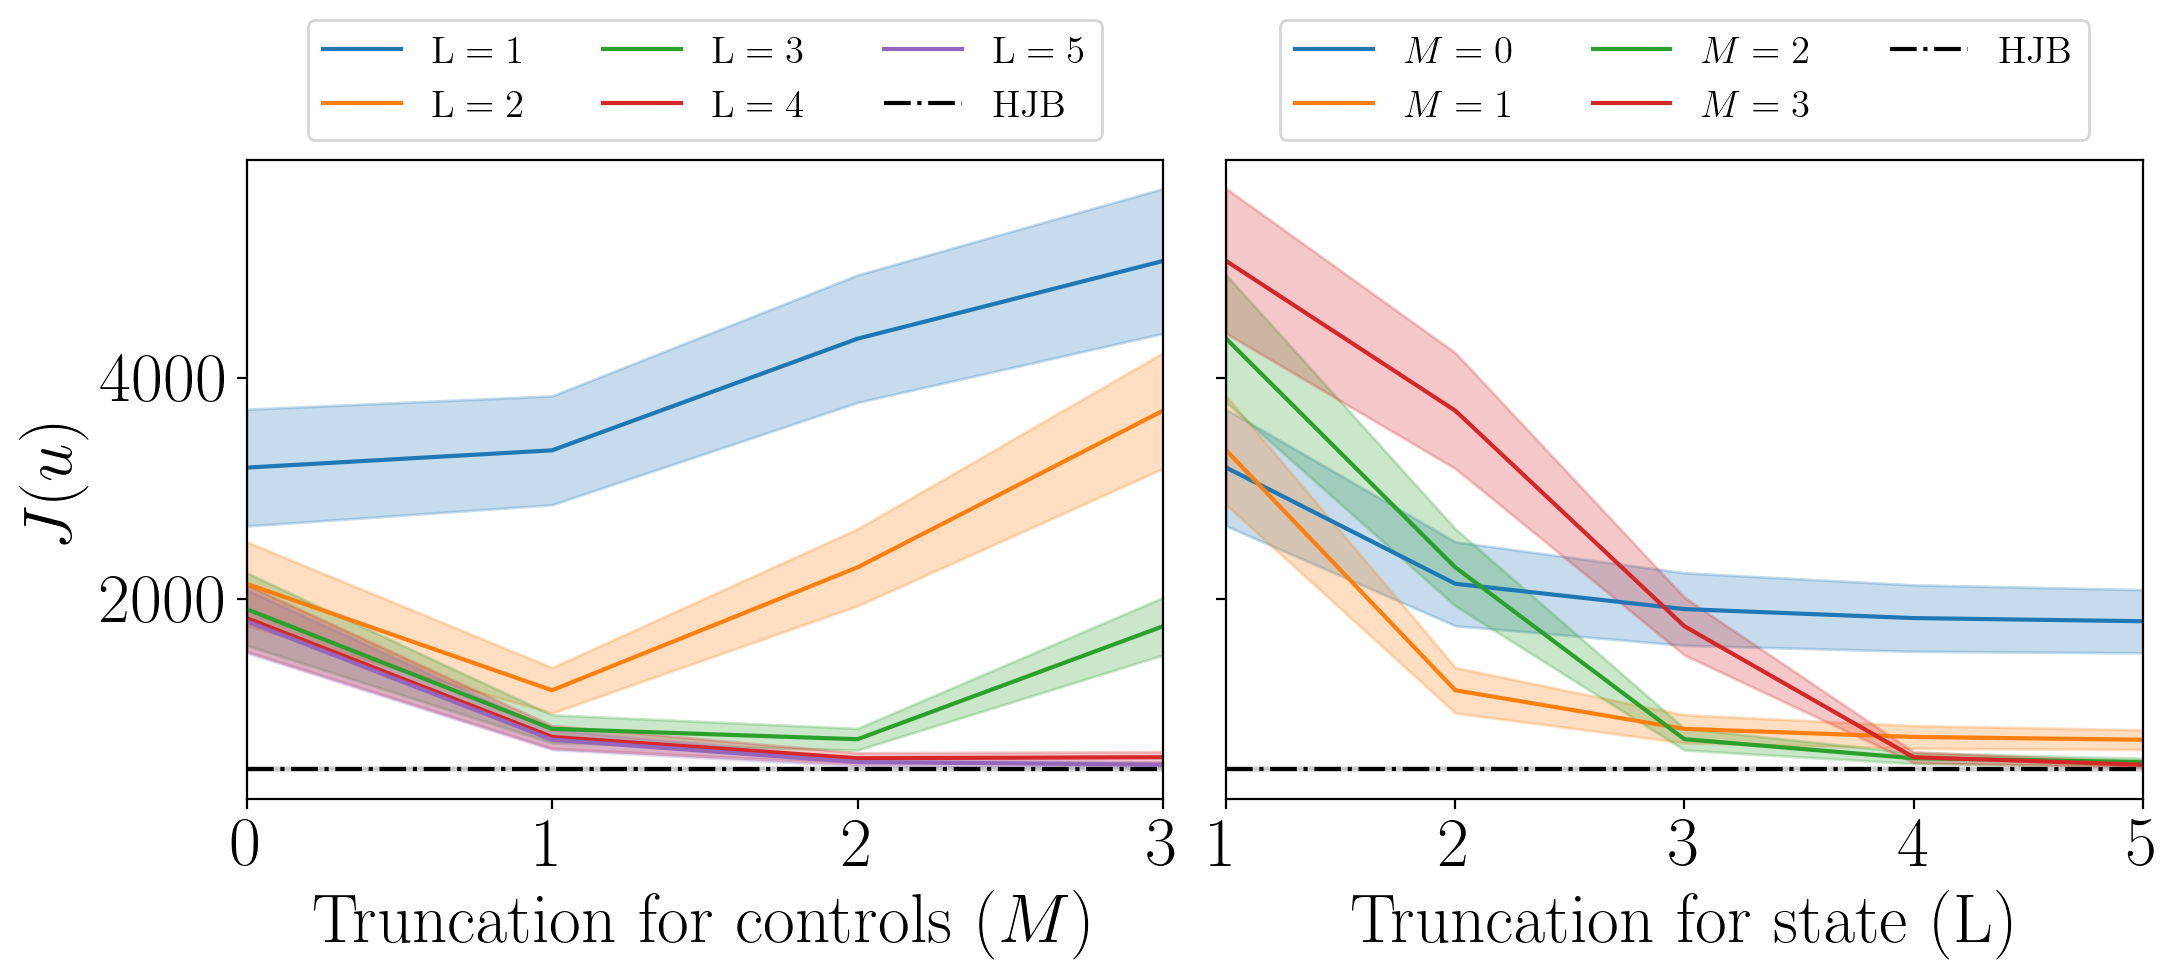

In [8]:
lev = 'L'

font1 = 25
font2 = 14

Z_val = 1.96

perform_hjb = sim_hjb['performance_mean']
perform_hjb_list = sim_hjb['performance_list']
perform_hjb_std = perform_hjb_list.std(ddof = 1)/np.sqrt(nsims)
perform_hjb_LCI = perform_hjb - Z_val*perform_hjb_std
perform_hjb_UCI = perform_hjb + Z_val*perform_hjb_std

fig, ax = plt.subplots(1, 2, figsize=(11,5), sharey='row')

for n, max_order_x in enumerate(max_order_x_list):
    perform = [experiment['performance_mean'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    perform_list = np.array([experiment['performance_list'] for experiment in sim_list if experiment['max_order_x']==max_order_x])
    perform_std = perform_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    perform_LCI = perform - Z_val*perform_std
    perform_UCI = perform + Z_val*perform_std
    ax[0].fill_between(max_order_F_list, perform_LCI, perform_UCI,alpha=0.25, color=f'C{n}')
    ax[0].plot(max_order_F_list, perform, label=rf'$\mathrm{{{lev}}} = {max_order_x}$', color=f'C{n}')
ax[0].set_xlabel(r'$\mathrm{Truncation}$ $\mathrm{for}$ $\mathrm{controls}$ $(M)$',  fontsize = font1)
ax[0].set_xticks(ticks=max_order_F_list)

for n, max_order_F in enumerate(max_order_F_list):
    perform = [experiment['performance_mean'] for experiment in sim_list if experiment['max_order_F']==max_order_F]
    perform_list = np.array([experiment['performance_list'] for experiment in sim_list if experiment['max_order_F']==max_order_F])
    perform_std = perform_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    perform_LCI = perform - Z_val*perform_std
    perform_UCI = perform + Z_val*perform_std
    ax[1].fill_between(max_order_x_list, perform_LCI, perform_UCI,alpha=0.25, color=f'C{n}')
    ax[1].plot(max_order_x_list, perform, label=rf'$M = {max_order_F}$', color=f'C{n}')
ax[1].set_xlabel(rf'$\mathrm{{Truncation}}$ $\mathrm{{for}}$ $\mathrm{{state}}$ $(\mathrm{{{lev}}})$',  fontsize = font1)
ax[1].set_xticks(ticks=max_order_x_list)

ax[0].set_ylabel(f'$J(u)$',  fontsize = font1)

for ax_i in ax:
    ax_i.tick_params(axis='both', which='major', labelsize=font1)
    #ax_i.set_yscale('log')
    ax_i.fill_between(ax_i.get_xticks(), perform_hjb_LCI, perform_hjb_UCI,alpha=0.25, color='grey')
    ax_i.axhline(perform_hjb, color = 'black', linestyle='-.', label=r'$\mathrm{HJB}$')
    ax_i.set_xlim(ax_i.get_xticks()[0], ax_i.get_xticks()[-1])

ax[0].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
ax[1].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
fig.savefig(f'figures/perform_diff_1.pdf',format='pdf',bbox_inches='tight')
plt.show()

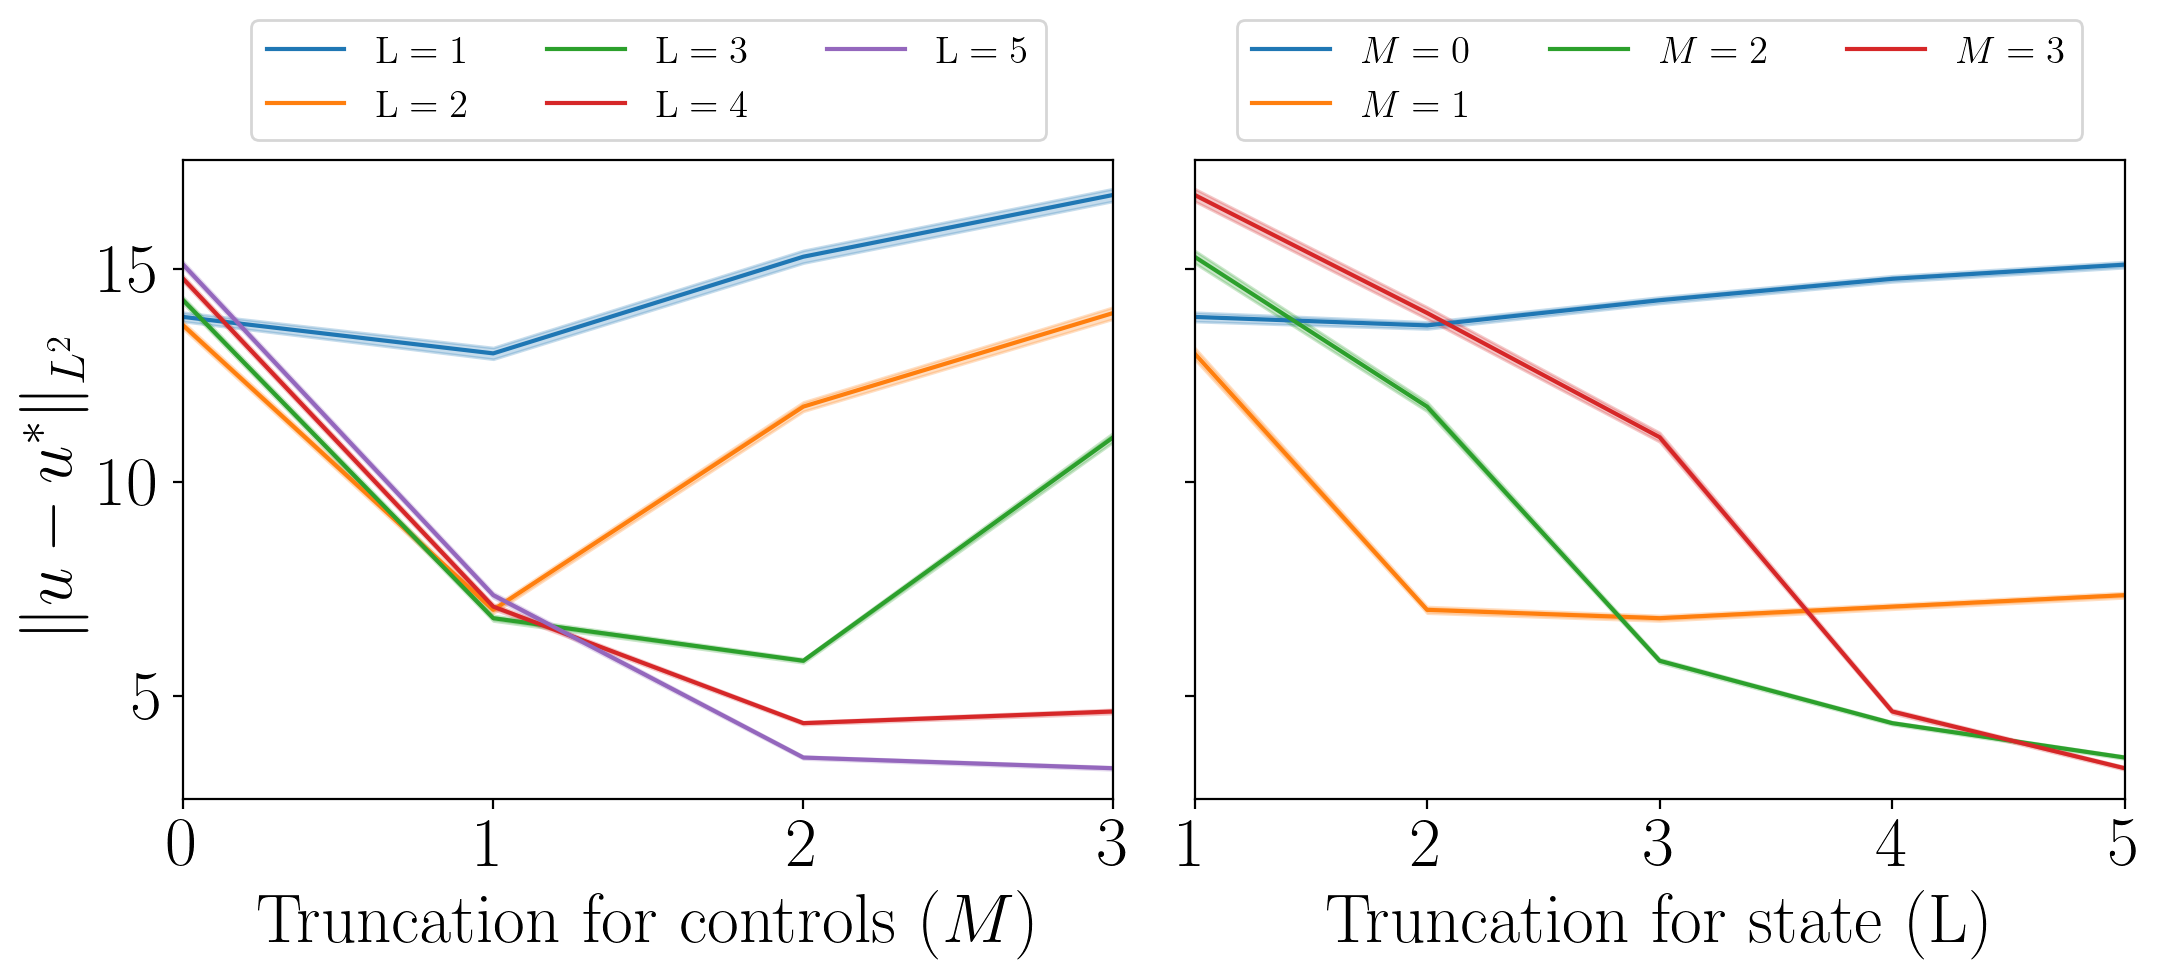

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11,5), sharey='row')

for n, max_order_x in enumerate(max_order_x_list):
    nu_L2_dist = [experiment['nu_L2_dist_mean'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    nu_L2_dist_list = np.array([experiment['nu_L2_dist_list'] for experiment in sim_list if experiment['max_order_x']==max_order_x])
    nu_L2_dist_std = nu_L2_dist_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    nu_L2_dist_LCI = nu_L2_dist - Z_val*nu_L2_dist_std
    nu_L2_dist_UCI = nu_L2_dist + Z_val*nu_L2_dist_std
    ax[0].fill_between(max_order_F_list, nu_L2_dist_LCI, nu_L2_dist_UCI,alpha=0.25, color=f'C{n}')
    ax[0].plot(max_order_F_list, nu_L2_dist, label=rf'$\mathrm{{{lev}}} = {max_order_x}$', color=f'C{n}')
ax[0].set_xlabel(r'$\mathrm{Truncation}$ $\mathrm{for}$ $\mathrm{controls}$ $(M)$',  fontsize = font1)
ax[0].set_xticks(ticks=max_order_F_list)

for n, max_order_F in enumerate(max_order_F_list):
    nu_L2_dist = [experiment['nu_L2_dist_mean'] for experiment in sim_list if experiment['max_order_F']==max_order_F]
    nu_L2_dist_list = np.array([experiment['nu_L2_dist_list'] for experiment in sim_list if experiment['max_order_F']==max_order_F])
    nu_L2_dist_std = nu_L2_dist_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    nu_L2_dist_LCI = nu_L2_dist - Z_val*nu_L2_dist_std
    nu_L2_dist_UCI = nu_L2_dist + Z_val*nu_L2_dist_std
    ax[1].fill_between(max_order_x_list, nu_L2_dist_LCI, nu_L2_dist_UCI,alpha=0.25, color=f'C{n}')
    ax[1].plot(max_order_x_list, nu_L2_dist, label=rf'$M = {max_order_F}$', color=f'C{n}')
ax[1].set_xlabel(rf'$\mathrm{{Truncation}}$ $\mathrm{{for}}$ $\mathrm{{state}}$ $(\mathrm{{{lev}}})$',  fontsize = font1)
ax[1].set_xticks(ticks=max_order_x_list)

ax[0].set_ylabel(r'$\|u - u^*\|_{L^2}$',  fontsize = font1)

for ax_i in ax:
    ax_i.tick_params(axis='both', which='major', labelsize=font1)
    ax_i.set_xlim(ax_i.get_xticks()[0], ax_i.get_xticks()[-1])

ax[0].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
ax[1].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
fig.savefig(f'figures/control_diff_1.pdf',format='pdf',bbox_inches='tight')
plt.show()

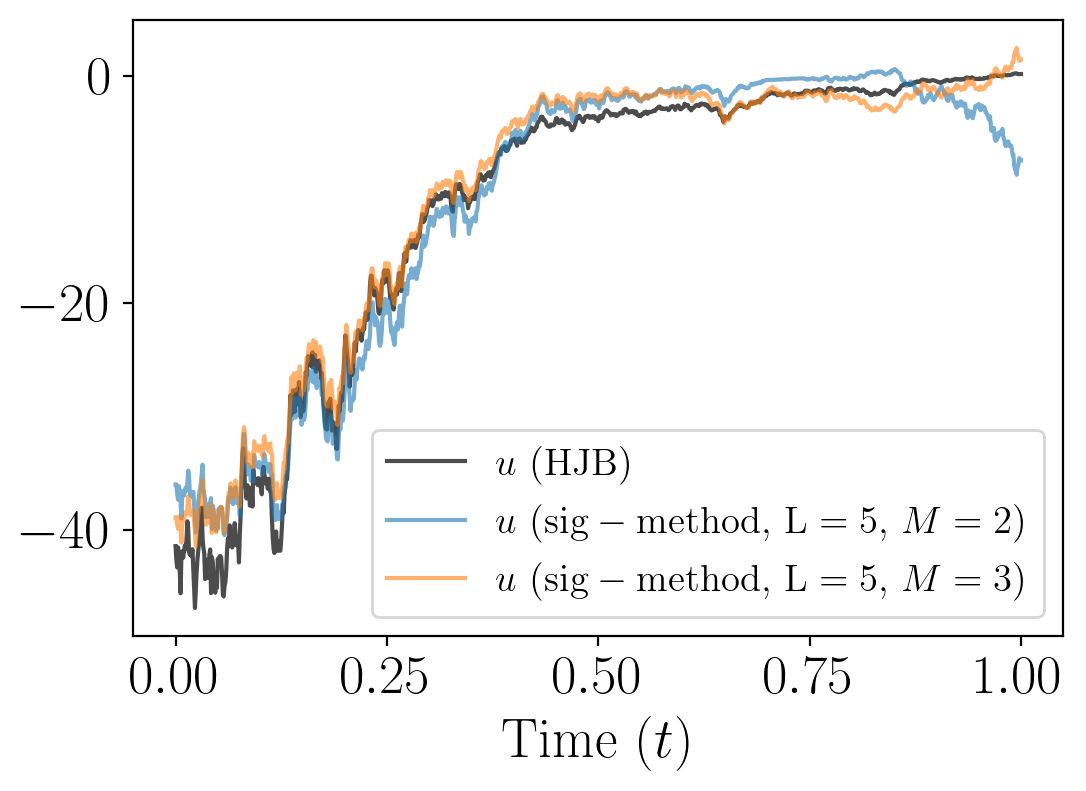

In [68]:
nsim = 1
font3 = 20
font4 = 14

fig, ax = plt.subplots(1, 1, figsize=(6,4))

max_order_x_1 = 5
max_order_F_1 = 2

max_order_x_2 = 5
max_order_F_2 = 3

nu_hjb = sim_hjb['nu_sims']
nu_1 = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x_1) and (sims['max_order_F'] == max_order_F_1)][0]
nu_2 = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x_2) and (sims['max_order_F'] == max_order_F_2)][0]

ax.plot(env.timesteps, nu_hjb[:,nsim], label=r'$u$ $\mathrm{(HJB)}$', color='black', alpha = 0.7)
ax.plot(env.timesteps, nu_1[:,nsim], label=rf'$u$ $(\mathrm{{sig-method}},$ $\mathrm{{{lev}}} = {max_order_x_1},$ $M = {max_order_F_1})$',
        alpha=0.6)
ax.plot(env.timesteps, nu_2[:,nsim], label=rf'$u$ $(\mathrm{{sig-method}},$ $\mathrm{{{lev}}} = {max_order_x_2},$ $M = {max_order_F_2})$',
        alpha=0.6)

ax.set_xlabel(rf'$\mathrm{{Time}}$ $(t)$',  fontsize = font3)
ax.tick_params(axis='both', which='major', labelsize=font3)

ax.legend(fontsize=font4, loc='lower right')
fig.savefig(f'figures/control_sample_path.pdf',format='pdf',bbox_inches='tight')
plt.show()

In [21]:
sim_list

[{'max_order_x': 1,
  'max_order_F': 0,
  'nu_sims': array([[-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         ...,
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5]]),
  'performance': np.float64(2574.3658713426657),
  'outperformance': np.float64(2119.001689591187),
  'nu_rmse': np.float64(14.744033557112038)},
 {'max_order_x': 1,
  'max_order_F': 1,
  'nu_sims': array([[-16.8       , -16.8       , -16.8       , ..., -16.8       ,
          -16.8       , -16.8       ],
         [-16.8       , -16.8       , -16.8       , ..., -16.8       ,
          -16.8       , -16.8       ],
         [-16.7748    , -16.7748    , -16.7748    , ..., -16.7748    ,
          -16.7748    , -16.7748    ],
         ...,
         [  8.32416666,   8.32416666,   8.32